In [1]:
1.What is GAN?
GAN stands for Generative Adversarial Network.
it is a Deep Learning architecture used to generate new data that look similar to the training data
for example;
-Generate human faces
- Generate handwritten digits
- generate cartoon images
- generate artificial product images
-generate realastic image

real an image from the original data set
fake image generated by the generator

SyntaxError: invalid syntax (3308930905.py, line 2)

In [4]:
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np



In [5]:
# Step 3: Load the MNIST dataset

# MNIST contains 70,000 handwritten digit images.
# - 60,000 training images.
# - 10,000 testing images.
# - Each image has dimensions 28 x 28.
# - Each image contains a digit between 0 and 9.



In [6]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

#check dataset shape
print("Training data ", x_train.shape)
print("Teasting data", x_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data  (60000, 28, 28)
Teasting data (10000, 28, 28)


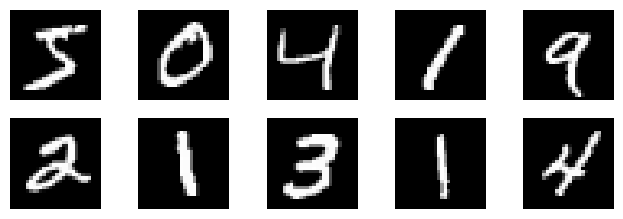

In [7]:
#Display some original images
plt.figure(figsize=(8,4))
for i in range(10):
    plt.subplot(3,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.axis('off')
plt.show()

In [8]:
# Step 4: Preprocess the images

# Our original pixel values range from 0 to 255.
# We need to normalize these values between -1 and +1.

# Why?
# Because our Generator will use the tanh activation function,
# which produces values between -1 and +1.

# Convert images to float32

x_train = x_train.astype("float32")

# Normalize pixel values from 0-255 to -1 to +1
x_train = (x_train - 127.5) / 127.5

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
print(x_train.shape)


# Why do we add the channel dimension?
# Because CNN models expect image data in this format:
# (height,width,channels)



(60000, 28, 28, 1)


In [9]:
# Step 5: Prepare the training dataset

BUFFER_SIZE = 60000
BATCH_SIZE = 256

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE)
train_dataset = train_dataset.batch(BATCH_SIZE)


# Explanation:
# - shuffle(): Randomly changes image order.

In [10]:
# Step 6: Create the Generator
# Now we will build our first neural network.
# The Generator takes 100 random numbers and generates a 28 × 28 image.
def build_generator():
    model = tf.keras.Sequential()
    # Input: 100 random numbers
    model.add(layers.Input(shape=(100,)))
    # Convert noise into 7*7*128 values
    model.add(layers.Dense(7 * 7 * 128))

    # Normalize values
    model.add(layers.BatchNormalization())

    # Apply activation
    model.add(layers.LeakyReLU())

    # Reshape into feature maps
    model.add(layers.Reshape((7, 7, 128)))

    # Increase image size from 7x7 to 14x14
    model.add(
        layers.Conv2DTranspose(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.BatchNormalization())

    model.add(layers.LeakyReLU())

    # Increase image size from 14x14 to 28x28
    model.add(
        layers.Conv2DTranspose(
            1,
            kernel_size=5,
            strides=2,
            padding="same",
            activation="tanh"
        )
    )

    return model

In [11]:
# Let's understand the important layers.
# Layer	                          Purpose
# Dense	                          Converts random noise into feature values
# Batch                           Normalization	Stabilizes training
# Leaky                           ReLU	Adds non-linearity
# Reshape                       	Converts features into 7 × 7 feature maps
# Conv2D                          Transpose	Upsamples feature maps
# Tanh	                          Generates pixel values between -1 and +1

In [12]:
# Creat the Generator:
generator = build_generator()
generator.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,864 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865,281 (3.30 MB)

 Trainable params: 852,609 (3.25 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [13]:
# Generate 1 random noise vector
noise = tf.random.normal([1, 100])
generated_image = generator(noise, training=False)
print(generated_image.shape)

(1, 28, 28, 1)


In [14]:
# Step 7: Create the Discriminator
# Now let's create the second neural network.
# The Discriminator receives an image and predicts whether it is real or fake.
def build_discriminator():

    model = tf.keras.Sequential()

    # Input image: 28x28 grayscale
    model.add(layers.Input(shape=(28, 28, 1)))

    # First convolution layer
    model.add(
        layers.Conv2D(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Second convolution layer
    model.add(
        layers.Conv2D(
            128,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Convert feature maps into a vector
    model.add(layers.Flatten())

    # Final output
    model.add(layers.Dense(1))

    return model

In [15]:
discriminator = build_discriminator()
discriminator.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Important: The final Dense layer has one output and no sigmoid activation. It produces a raw score called a logit.
# - Higher score: More likely to be real.
# - Lower score: More likely to be fake.
# We will use BinaryCrossentropy(from_logits=True) to calculate the loss.
# Step 8: Define loss functions
# Now comes the most important part of GAN training.
# We need two loss functions.
# 1. Generator Loss
# 2. Discriminator Loss

In [17]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

In [18]:
# Discriminator Loss:
# The Discriminator should identify real images as 1 and fake images as 0.
def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss

In [19]:
def generator_loss(fake_output):

    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

In [20]:
# Step 9: Define optimizers
# We use Adam optimizers to update the weights of both networks.
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

# Why two optimizers?
# Because the Generator and Discriminator have different trainable weights
# and are trained separately.

In [21]:
# Define noise dimension

noise_dim = 100


@tf.function
def train_step(real_images):

    # Number of images in current batch
    batch_size = tf.shape(real_images)[0]

    # Generate random noise
    noise = tf.random.normal([batch_size, noise_dim])

    # --------------------------------
    # Train Discriminator
    # --------------------------------

    with tf.GradientTape() as disc_tape:

        # Generate fake images
        generated_images = generator(noise, training=True)

        # Discriminator predictions on real images
        real_output = discriminator(
            real_images,
            training=True
        )

        # Discriminator predictions on fake images
        fake_output = discriminator(
            tf.stop_gradient(generated_images),
            training=True
        )

        # Calculate discriminator loss
        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    # Calculate gradients
    disc_gradients = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    # Update discriminator weights
    discriminator_optimizer.apply_gradients(
        zip(
            disc_gradients,
            discriminator.trainable_variables
        )
    )

    # --------------------------------
    # Train Generator
    # --------------------------------

    noise = tf.random.normal([batch_size, noise_dim])

    with tf.GradientTape() as gen_tape:

        # Generate new fake images
        generated_images = generator(
            noise,
            training=True
        )

        # Ask discriminator to classify fake images
        fake_output = discriminator(
            generated_images,
            training=True
        )

        # Generator wants fake images to be classified as real
        gen_loss = generator_loss(fake_output)

    # Calculate generator gradients
    gen_gradients = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    # Update generator weights
    generator_optimizer.apply_gradients(
        zip(
            gen_gradients,
            generator.trainable_variables
        )
    )

    return gen_loss, disc_loss

In [22]:
# Step 11: Train the GAN model
# Now we will train both networks.
EPOCHS = 30

for epoch in range(EPOCHS):

    gen_loss_total = 0
    disc_loss_total = 0
    batches = 0

    for image_batch in train_dataset:

        gen_loss, disc_loss = train_step(image_batch)

        gen_loss_total += gen_loss
        disc_loss_total += disc_loss

        batches += 1

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {gen_loss_total / batches:.4f} | "
        f"Discriminator Loss: {disc_loss_total / batches:.4f}"
    )

Epoch 1/30 | Generator Loss: 0.7896 | Discriminator Loss: 1.1772
Epoch 2/30 | Generator Loss: 0.7712 | Discriminator Loss: 1.3362
Epoch 3/30 | Generator Loss: 0.7882 | Discriminator Loss: 1.3258
Epoch 4/30 | Generator Loss: 0.8251 | Discriminator Loss: 1.2747
Epoch 5/30 | Generator Loss: 0.8898 | Discriminator Loss: 1.2224
Epoch 6/30 | Generator Loss: 0.9116 | Discriminator Loss: 1.2085
Epoch 7/30 | Generator Loss: 0.8904 | Discriminator Loss: 1.2482
Epoch 8/30 | Generator Loss: 0.8697 | Discriminator Loss: 1.2622
Epoch 9/30 | Generator Loss: 0.8612 | Discriminator Loss: 1.2760
Epoch 10/30 | Generator Loss: 0.8476 | Discriminator Loss: 1.2761
Epoch 11/30 | Generator Loss: 0.8471 | Discriminator Loss: 1.2859
Epoch 12/30 | Generator Loss: 0.8408 | Discriminator Loss: 1.2878
Epoch 13/30 | Generator Loss: 0.8360 | Discriminator Loss: 1.2869
Epoch 14/30 | Generator Loss: 0.8440 | Discriminator Loss: 1.2881
Epoch 15/30 | Generator Loss: 0.8495 | Discriminator Loss: 1.2882
Epoch 16/30 | Gener

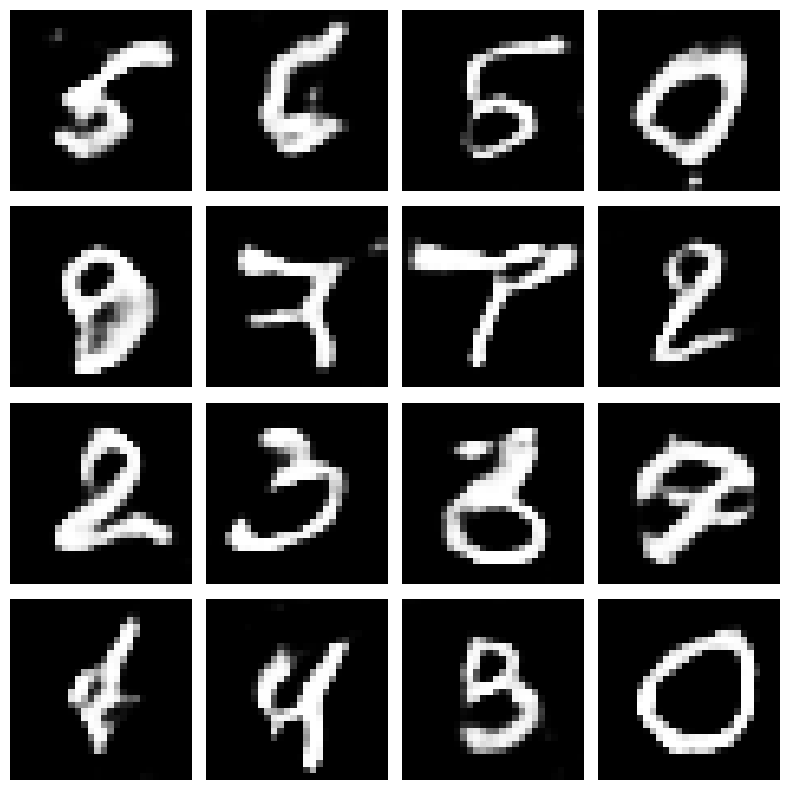

In [23]:
# Step 12: Generate new images
# Final output
# Now our Generator has learned from the MNIST dataset.
# Let's generate 16 new images.
# Generate 16 random noise vectors

noise = tf.random.normal([16, noise_dim])

# Generate images

predictions = generator(noise, training=False)

# Display generated images

plt.figure(figsize=(8, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    # Convert pixel values from -1 to +1 into 0 to 1
    image = (predictions[i, :, :, 0] + 1) / 2

    plt.imshow(image, cmap="gray")

    plt.axis("off")

plt.tight_layout()

plt.show()